<a href="https://colab.research.google.com/github/ActLuisGutierrezVanegas/Loan_Default_Risk_Prediction_With_ML/blob/main/notebook/Loan_Default_Risk_Prediction_With_ML_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup Google Colab.

In [1]:
# Configuration required to be able to read files from my Drive.
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## Libraries

In [2]:
# ----------------- EDA ------------------------
import pandas as pd
import numpy as np
# ----------------- Data visualization ------------------------
import seaborn as sns
import matplotlib.pyplot as plt
# ----------------- Models ------------------------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
import xgboost as xgb


In [3]:
pd.set_option("display.max_columns", None)

## Data load

In [4]:
# The path to the files stored in Google Drive is specified.
directory = "/content/drive/MyDrive/Data_Science/Github_Portfolio/"
file_1 = "Loan_Default_Risk_Prediction_With_ML"
path_1 = f"{directory}{file_1}/" + "data_loan_default_risk.xlsx"


In [5]:
df = pd.read_excel(path_1)

# 1.- EDA

## 1.1.- Overview

In [6]:
# Dataframe dimensions are checked.
df.shape

(14067, 55)

In [7]:
# Column names and data types are displayed.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14067 entries, 0 to 14066
Data columns (total 55 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   ID                         14067 non-null  int64  
 1   ind_malo                   14067 non-null  int64  
 2   hora_reg_norm              14067 non-null  float64
 3   dia_reg                    14067 non-null  int64  
 4   medio_contacto_grupo       14067 non-null  object 
 5   tipo_mail_rango            14067 non-null  object 
 6   ingreso_propio_norm        14058 non-null  float64
 7   edad_norm                  14067 non-null  float64
 8   sexo                       14067 non-null  object 
 9   nivel_estudios             14067 non-null  object 
 10  Estado                     14067 non-null  object 
 11  destino                    14067 non-null  int64  
 12  act_eco                    14067 non-null  object 
 13  ing_cuota_pf_rv            14061 non-null  flo

In [8]:
df.head()

,ID,ind_malo,hora_reg_norm,dia_reg,medio_contacto_grupo,tipo_mail_rango,ingreso_propio_norm,edad_norm,sexo,nivel_estudios,Estado,destino,act_eco,ing_cuota_pf_rv,cuota_mensual_fijos,cuota_mensual_revolventes,hist_suf_pf_norm,hist_suf_rv_norm,bc_score_norm,icc_norm,monto_prom_norm,porc_deuda_12m_norm,porc_fijos_norm,porc_saldo_fijos_norm,pagos_suf_limite_norm,pagos_suf_limite_RV_norm,creditos_general_norm,creditos_general_ab_norm,creditos_recientes_norm,Saldo_Vencido_act_norm,Saldo_Actual_PF_norm,Saldo_Actual_RV_norm,porc_deuda_rev_norm,pagos_suf_limite_PF_norm,porc_mop_1_norm,ind_mop_4_9_norm,mop_max_act_norm,BANCO_HIP,BANCO_RV,BANCO_PF,AUTO,TIENDA_COMERCIAL,FINANCIERA,MICROFINANCIERA,COMUNICACIONES,con_2m_norm,BURO_DE_CREDITO_C,BANCO_C,SOLICITUDES_PREVIAS_C,SIC_C,FINANCIERA_C,CONSUMIDOR_FINAL_C,MICROFINANCIERA_C,TIENDA_COMERCIAL_C,BANCOS_C
0,1058,0,1.000000,1,Facebook,gma,1.000000,0.010601,Hombre,Maestria,CDMX,6,Empleado,0.510333,30000,620,0.364,0.380,0.724458,0.750,1.00000,1.000000,0.647059,0.914303,0.608,0.494,0.34,0.25,0.833333,0.0,1.000000,0.770653,0.717982,0.1425,1.000000,0.0,0.111111,0.058824,0.235294,0.117647,0.0,0.058824,0.235294,0.0,0.000000,0.000000,0.375000,0.250000,0.125000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
1,1596,0,0.652174,3,Facebook,correo_otro,0.000000,0.006562,Hombre,Licenciatura,Queretaro de Arteaga,4,Empleado,0.234250,0,937,0.324,0.648,0.606811,0.875,0.06172,0.249687,0.388889,0.000000,0.628,0.338,0.24,0.15,1.000000,0.0,0.000000,0.089980,0.792356,0.3625,0.250814,0.0,0.111111,0.000000,0.222222,0.111111,0.0,0.166667,0.166667,0.0,0.222222,0.266667,0.166667,0.208333,0.083333,0.208333,0.041667,0.083333,0.041667,0.041667,0.0
2,1981,0,0.521739,6,Facebook,hot,0.000000,0.017668,Hombre,Maestria,Estado de México,6,Empleado,1.000000,10559,10000,0.048,1.000,0.767802,0.750,1.00000,1.000000,0.000000,0.500000,0.000,1.000,0.24,0.55,0.916667,0.0,1.000000,1.000000,0.960103,0.0300,1.000000,0.0,0.000000,0.000000,0.500000,0.062500,0.0,0.125000,0.062500,0.0,0.187500,0.066667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0
3,2243,0,0.826087,7,Facebook,hot,0.142857,0.006562,Mujer,Licenciatura,CDMX,6,Empleado,0.095917,0,1151,0.396,0.392,0.730650,0.750,0.01125,0.249687,0.083333,0.000000,0.632,0.544,0.20,0.20,0.800000,0.0,0.000000,0.177907,0.869251,0.1100,0.895833,0.0,0.111111,0.000000,0.666667,0.083333,0.0,0.000000,0.083333,0.0,0.083333,0.333333,0.384615,0.192308,0.076923,0.076923,0.076923,0.076923,0.000000,0.038462,0.0
4,4233,0,0.652174,3,Otro_medio,gma,0.280679,0.005553,Hombre,Licenciatura,CDMX,1,Empleado,0.284410,4208,1400,0.128,0.308,0.668731,0.875,0.01500,0.249687,0.166667,0.397942,0.418,0.354,0.12,0.25,1.000000,0.0,0.039288,0.099067,0.544302,0.0800,0.904762,0.2,0.111111,0.000000,0.500000,0.166667,0.0,0.333333,0.000000,0.0,0.000000,0.000000,0.333333,0.000000,0.333333,0.000000,0.000000,0.000000,0.000000,0.333333,0.0


In [9]:
df.tail()

,ID,ind_malo,hora_reg_norm,dia_reg,medio_contacto_grupo,tipo_mail_rango,ingreso_propio_norm,edad_norm,sexo,nivel_estudios,Estado,destino,act_eco,ing_cuota_pf_rv,cuota_mensual_fijos,cuota_mensual_revolventes,hist_suf_pf_norm,hist_suf_rv_norm,bc_score_norm,icc_norm,monto_prom_norm,porc_deuda_12m_norm,porc_fijos_norm,porc_saldo_fijos_norm,pagos_suf_limite_norm,pagos_suf_limite_RV_norm,creditos_general_norm,creditos_general_ab_norm,creditos_recientes_norm,Saldo_Vencido_act_norm,Saldo_Actual_PF_norm,Saldo_Actual_RV_norm,porc_deuda_rev_norm,pagos_suf_limite_PF_norm,porc_mop_1_norm,ind_mop_4_9_norm,mop_max_act_norm,BANCO_HIP,BANCO_RV,BANCO_PF,AUTO,TIENDA_COMERCIAL,FINANCIERA,MICROFINANCIERA,COMUNICACIONES,con_2m_norm,BURO_DE_CREDITO_C,BANCO_C,SOLICITUDES_PREVIAS_C,SIC_C,FINANCIERA_C,CONSUMIDOR_FINAL_C,MICROFINANCIERA_C,TIENDA_COMERCIAL_C,BANCOS_C
14062,1967073,0,0.739130,5,El Mejor Trato,hot,0.142857,0.002019,Mujer,Bachillerato,Chiapas,2,Comerciante,0.264167,737,2433,0.040,0.200,0.721362,0.625,0.028875,1.000000,0.083333,0.095516,0.344,0.324,0.20,0.45,0.900,0.0,0.010532,0.166220,0.474462,0.0250,0.925094,0.0,0.111111,0.0,0.083333,0.000000,0.0,0.583333,0.166667,0.0,0.166667,0.200000,0.250000,0.166667,0.083333,0.083333,0.250000,0.000000,0.0,0.000000,0.083333
14063,1967074,0,0.739130,5,YoTePresto,hot,0.107143,0.003534,Hombre,Licenciatura,Tabasco,3,Comerciante,0.057200,0,572,0.092,0.256,0.585139,0.500,0.000000,0.249687,0.666667,0.000000,0.242,0.212,0.26,0.15,0.500,0.0,0.000000,0.078780,0.729444,0.0375,0.185751,0.0,0.111111,0.0,0.066667,0.066667,0.0,0.200000,0.533333,0.0,0.066667,0.066667,0.366667,0.133333,0.033333,0.033333,0.133333,0.000000,0.0,0.100000,0.000000
14064,1967283,0,0.826087,5,Facebook,gma,0.080357,0.011610,Hombre,Secundaria,Baja California,6,Empleado,1.000000,5616,4690,0.152,0.684,0.681115,0.750,0.000000,0.249687,0.285714,0.494326,0.242,0.166,0.12,0.15,1.000,0.0,0.156648,0.267073,0.552566,0.0950,0.913044,0.1,0.111111,0.0,0.571429,0.142857,0.0,0.000000,0.000000,0.0,0.142857,0.133333,0.300000,0.200000,0.200000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
14065,1967565,0,0.086957,6,Campana GL,gma,0.107143,0.000505,Hombre,Bachillerato,Guerrero,3,Empleado,0.171700,1717,0,0.012,0.180,0.761610,0.875,0.075000,1.000000,0.250000,0.906308,0.130,0.124,0.06,0.15,1.000,0.0,0.054712,0.009427,0.372989,0.0075,0.918699,0.0,0.111111,0.0,0.000000,0.000000,0.0,0.500000,0.000000,0.0,0.250000,0.133333,0.333333,0.296296,0.074074,0.037037,0.037037,0.000000,0.0,0.074074,0.000000
14066,1967660,0,0.347826,6,Otro_medio,correo_otro,1.000000,0.007067,Hombre,Licenciatura,CDMX,6,Empleado,0.211200,9840,2832,0.540,0.640,0.758514,0.500,0.134904,0.285813,0.178571,0.658029,1.000,1.000,0.50,0.50,0.625,0.0,0.710640,0.615520,0.521536,0.2775,0.991364,0.0,0.111111,0.0,0.428571,0.142857,0.0,0.178571,0.071429,0.0,0.071429,0.200000,0.358974,0.435897,0.025641,0.051282,0.000000,0.025641,0.0,0.076923,0.025641


The dataset contains 14,067 credit applications and 55 variables describing demographic, financial, credit history, and behavioral information.

In [10]:
# Missing values ​​in the dataset are checked.
print(df.isnull().sum())

ID                           0
ind_malo                     0
hora_reg_norm                0
dia_reg                      0
medio_contacto_grupo         0
tipo_mail_rango              0
ingreso_propio_norm          9
edad_norm                    0
sexo                         0
nivel_estudios               0
Estado                       0
destino                      0
act_eco                      0
ing_cuota_pf_rv              6
cuota_mensual_fijos          0
cuota_mensual_revolventes    0
hist_suf_pf_norm             0
hist_suf_rv_norm             0
bc_score_norm                0
icc_norm                     0
monto_prom_norm              0
porc_deuda_12m_norm          0
porc_fijos_norm              0
porc_saldo_fijos_norm        0
pagos_suf_limite_norm        0
pagos_suf_limite_RV_norm     0
creditos_general_norm        0
creditos_general_ab_norm     0
creditos_recientes_norm      0
Saldo_Vencido_act_norm       0
Saldo_Actual_PF_norm         0
Saldo_Actual_RV_norm         0
porc_deu

We can observe that columns "ingreso_propio_norm" and "ing_cuota_pf_rv" contain null values.

In [11]:
# Zoom in on columns with missing values.
print(df[["ingreso_propio_norm", "ing_cuota_pf_rv"]].isnull().sum())

ingreso_propio_norm    9
ing_cuota_pf_rv        6
dtype: int64


Missing values are limited to two numerical variables and will be handled during preprocessing.

In [12]:
# We verify how many unique IDs we have.
df["ID"].nunique()

14067

In [13]:
df.shape[0]

14067

The ID column was reviewed to verify record uniqueness. Since it is only an identifier and does not provide predictive information, it was excluded from the modeling features.

In [14]:
# We check for duplicate records across all columns.
df.duplicated().sum()

np.int64(0)

No duplicated records were found in the dataset.

## 1.2.- Categorical variables

In [15]:
# The categorical variables to be explored are defined below.
columnas_categoricas = [
    "dia_reg",
    "medio_contacto_grupo",
    "tipo_mail_rango",
    "sexo",
    "nivel_estudios",
    "Estado",
    "destino",
    "act_eco"
    ]

In [16]:
for columna in columnas_categoricas:

    conteo = df[columna].value_counts()

    porcentaje = (
        df[columna]
        .value_counts(normalize = True)
        .mul(100)
        .round(2)
    )

    resumen = pd.DataFrame({
        "Conteo": conteo,
        "Porcentaje": porcentaje.map(lambda x: f"{x:.2f}%")
    })

    print(f"\n--- {columna} ---")
    display(resumen)


--- dia_reg ---


,Conteo,Porcentaje
dia_reg,,
3,2720,19.34%
2,2623,18.65%
4,2468,17.54%
5,2282,16.22%
6,1876,13.34%
7,1088,7.73%
1,1010,7.18%



--- medio_contacto_grupo ---


,Conteo,Porcentaje
medio_contacto_grupo,,
Otro_medio,4805,34.16%
Campana GL,3400,24.17%
El Mejor Trato,2174,15.45%
Facebook,1853,13.17%
SOLCREDITO,1302,9.26%
YoTePresto,533,3.79%



--- tipo_mail_rango ---


...

,Conteo,Porcentaje
Estado,,
CDMX,3804,27.04%
Estado de México,3102,22.05%
Jalisco,929,6.60%
Nuevo Leon,544,3.87%
Veracruz Llave,452,3.21%
Puebla,402,2.86%
Guanajuato,381,2.71%
Queretaro de Arteaga,372,2.64%
Baja California,314,2.23%



--- destino ---


,Conteo,Porcentaje
destino,,
6,5415,38.49%
3,1484,10.55%
2,1433,10.19%
1,1351,9.60%
7,854,6.07%
4,844,6.00%
11,832,5.91%
9,603,4.29%
8,556,3.95%



--- act_eco ---


,Conteo,Porcentaje
act_eco,,
Empleado,10962,77.93%
Comerciante,3105,22.07%


The categorical variables were reviewed to understand their cardinality and distribution. No additional transformations are applied at this stage. Encoding decisions will be addressed during preprocessing.

## 1.3 Numerical variables

In [17]:
# Quantitative variables are checked to verify whether they are normalized.
df.loc[:, ~df.columns.isin(columnas_categoricas + ["ID", "ind_malo"])].describe()

,hora_reg_norm,ingreso_propio_norm,edad_norm,ing_cuota_pf_rv,cuota_mensual_fijos,cuota_mensual_revolventes,hist_suf_pf_norm,hist_suf_rv_norm,bc_score_norm,icc_norm,monto_prom_norm,porc_deuda_12m_norm,porc_fijos_norm,porc_saldo_fijos_norm,pagos_suf_limite_norm,pagos_suf_limite_RV_norm,creditos_general_norm,creditos_general_ab_norm,creditos_recientes_norm,Saldo_Vencido_act_norm,Saldo_Actual_PF_norm,Saldo_Actual_RV_norm,porc_deuda_rev_norm,pagos_suf_limite_PF_norm,porc_mop_1_norm,ind_mop_4_9_norm,mop_max_act_norm,BANCO_HIP,BANCO_RV,BANCO_PF,AUTO,TIENDA_COMERCIAL,FINANCIERA,MICROFINANCIERA,COMUNICACIONES,con_2m_norm,BURO_DE_CREDITO_C,BANCO_C,SOLICITUDES_PREVIAS_C,SIC_C,FINANCIERA_C,CONSUMIDOR_FINAL_C,MICROFINANCIERA_C,TIENDA_COMERCIAL_C,BANCOS_C
count,14067.000000,14058.000000,14067.000000,14061.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000,14067.000000
mean,0.609490,0.232445,0.009285,0.385624,4679.977465,1822.829601,0.228110,0.360832,0.702139,0.709888,0.151295,0.402802,0.416238,0.531917,0.468385,0.340178,0.228316,0.224326,0.769662,0.028520,0.235847,0.249794,0.514732,0.222981,0.841019,0.119087,0.118394,0.020821,0.323443,0.154691,0.012885,0.193932,0.081674,0.026150,0.093041,0.183218,0.270636,0.300360,0.101496,0.087429,0.052807,0.046866,0.014337,0.025643,0.018377
std,0.213742,0.231170,0.009782,0.321293,6249.938337,2507.064954,0.206918,0.253297,0.065174,0.182848,0.209688,0.288749,0.297485,0.396145,0.352121,0.328397,0.202181,0.148132,0.249701,0.151723,0.323910,0.303410,0.341921,0.255484,0.206403,0.257597,0.051361,0.057501,0.255540,0.195075,0.048199,0.238855,0.167715,0.101266,0.130565,0.171157,0.148099,0.177101,0.088174,0.094506,0.077871,0.072017,0.040864,0.054478,0.045747
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.563467,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.478261,0.076786,0.005553,0.111818,0.000000,0.000000,0.044000,0.156000,0.653251,0.625000,0.026355,0.249687,0.176471,0.000000,0.148000,0.068000,0.080000,0.100000,0.600000,0.000000,0.000000,0.026233,0.208762,0.025000,0.797980,0.000000,0.111111,0.000000,0.111111,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.066667,0.181818,0.173913,0.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.608696,0.160714,0.008077,0.305448,2542.000000,845.000000,0.196000,0.316000,0.705882,0.750000,0.074400,0.249687,0.400000,0.615173,0.384000,0.224000,0.180000,0.200000,0.833333,0.000000,0.075196,0.120993,0.548991,0.130000,0.913420,0.000000,0.111111,0.000000,0.300000,0.090909,0.000000,0.107143,0.000000,0.000000,0.036364,0.133333,0.272727,0.300000,0.076923,0.071429,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.760870,0.285714,0.012115,0.599500,6428.500000,2373.500000,0.352000,0.520000,0.749226,0.875000,0.178511,0.403643,0.666667,0.925806,0.820000,0.536000,0.300000,0.300000,1.000000,0.000000,0.347490,0.350267,0.824201,0.327500,0.974359,0.100000,0.111111,0.000000,0.500000,0.250000,0.000000,0.312500,0.090909,0.000000,0.142857,0.266667,0.357143,0.416667,0.125000,0.142857,0.083333,0.076923,0.000000,0.033060,0.000000
max,1.000000,1.000000,1.000000,1.000000,30000.000000,10000.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000

In [18]:
# Zoom in on non-normalized quantitative variables.
df.loc[:, ["cuota_mensual_fijos", "cuota_mensual_revolventes"]].describe()

,cuota_mensual_fijos,cuota_mensual_revolventes
count,14067.000000,14067.000000
mean,4679.977465,1822.829601
std,6249.938337,2507.064954
min,0.000000,0.000000
25%,0.000000,0.000000
50%,2542.000000,845.000000
75%,6428.500000,2373.500000
max,30000.000000,10000.000000


### 1.3.1 Key risk variables

In [19]:
# The key risk variables to be explored are defined below.
key_numeric_variables = [
    "bc_score_norm",
    "cuota_mensual_fijos",
    "cuota_mensual_revolventes",
    "ind_mop_4_9_norm"
]

In [20]:
df[key_numeric_variables].describe()

,bc_score_norm,cuota_mensual_fijos,cuota_mensual_revolventes,ind_mop_4_9_norm
count,14067.000000,14067.000000,14067.000000,14067.000000
mean,0.702139,4679.977465,1822.829601,0.119087
std,0.065174,6249.938337,2507.064954,0.257597
min,0.563467,0.000000,0.000000,0.000000
25%,0.653251,0.000000,0.000000,0.000000
50%,0.705882,2542.000000,845.000000,0.000000
75%,0.749226,6428.500000,2373.500000,0.100000
max,1.000000,30000.000000,10000.000000,1.000000


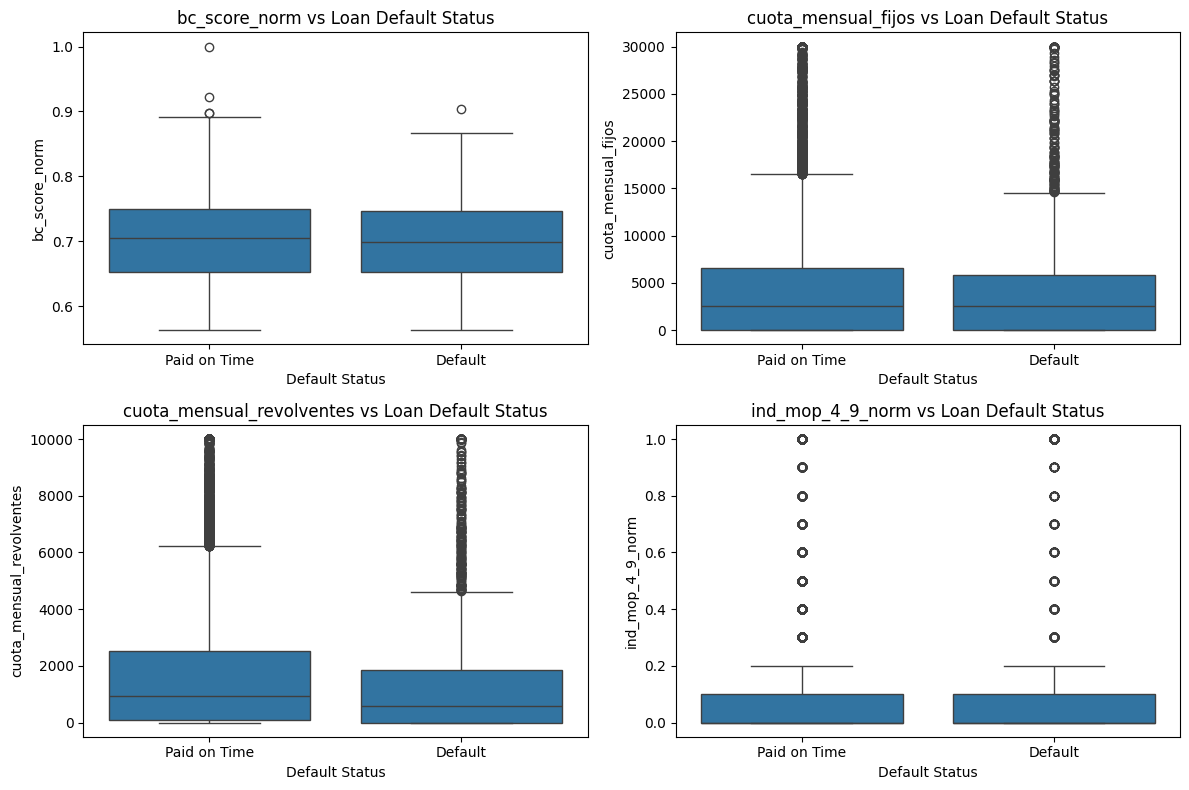

In [21]:
fig, axes = plt.subplots(
    2,
    2,
    figsize = (12, 8)
)

axes = axes.flatten()

for i, column in enumerate(key_numeric_variables):

    sns.boxplot(
        data = df,
        x = "ind_malo",
        y = column,
        ax = axes[i]
    )

    axes[i].set_title(
        f"{column} vs Loan Default Status"
    )

    axes[i].set_xlabel("Default Status")

    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(
        ["Paid on Time", "Default"]
    )

plt.tight_layout()
plt.show()

The key risk variables show different distribution patterns.

In particular, "cuota_mensual_fijos" and "cuota_mensual_revolventes" present strong right-skewed distributions, with most observations concentrated at relatively low values and a smaller number of cases showing considerably higher monthly payment amounts.
This suggests the presence of high-payment observations that may represent customers with greater financial commitments.

"bc_score_norm" shows a more compact and relatively symmetric distribution compared with the other key risk variables. As a normalized credit score, it provides a direct measure of customer risk and may offer useful discriminatory power when distinguishing between lower- and higher-risk applicants.

"ind_mop_4_9_norm" shows a strong concentration near zero, with fewer observations at higher values. This suggests that most customers have limited or no presence of severe payment delinquency indicators, while a smaller group exhibits more adverse credit behavior. Given its direct relationship with payment history, this variable may provide an important signal for identifying higher-risk customers.

These distributions should be considered during preprocessing, especially for models that are sensitive to scale and extreme values. However, no transformation is applied at this stage solely because of skewness.

## 1.4.- Target distribution

The target variable "ind_malo" was analyzed to evaluate its class distribution.

In [22]:
df["ind_malo"].value_counts()

,count
ind_malo,
0,11097
1,2970


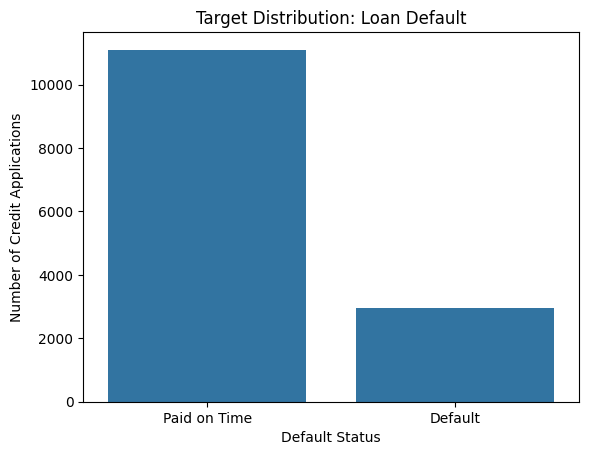

In [23]:
sns.countplot(data = df, x = "ind_malo")
plt.title("Target Distribution: Loan Default")
plt.xlabel("Default Status")
plt.ylabel("Number of Credit Applications")
plt.xticks(
    ticks=[0, 1],
    labels=["Paid on Time", "Default"]
)
plt.show()

The target variable is imbalanced. Approximately 79% of the observations belong to class 0 (paid on time), while 21% belong to class 1 (default). This type of imbalance is common in credit risk problems and should be considered during model training and evaluation.

Most customers paid on time, while a smaller proportion defaulted. Therefore, model performance should not be evaluated using accuracy alone, since a model could achieve a high accuracy by favoring the majority class while still failing to correctly identify high-risk customers.

## 1.5.- Correlation matrix

In [24]:
# A copy of the dataframe was created to maintain traceability.
df_corr_aux = df.copy()

An auxiliar dataframe is created to apply encoder to categorical variables.

In [25]:
dicc_estudios = {
    "Sin estudios": 0,
    "Primaria": 1,
    "Secundaria": 2,
    "Bachillerato": 3,
    "Licenciatura": 4,
    "Maestria": 5,
    "Doctorado": 6
}

In [26]:
df_corr_aux["nivel_estudios"] = df_corr_aux["nivel_estudios"].map(dicc_estudios)

In [27]:
columnas_one_hot = ["medio_contacto_grupo", "tipo_mail_rango", "sexo", "Estado", "act_eco"]

In [28]:
df_corr = pd.get_dummies(
    df_corr_aux,
    columns = columnas_one_hot,
    drop_first = True
)

In [29]:
tabla_corr = df_corr.corr()


Only the highest correlations among all the variables are shown, with values ​​between [-1, -0.6) and (0.6, 1]

In [30]:
lista_pares = tabla_corr.unstack()
pares_ordenados = lista_pares.sort_values(ascending = False)

filtro_alta_corr = pares_ordenados[
    ((pares_ordenados >= 0.60) & (pares_ordenados < 1.0)) |
    ((pares_ordenados <= -0.60) & (pares_ordenados > -1.0))
]

tabla_alta_corr = pd.DataFrame(filtro_alta_corr).reset_index()

tabla_alta_corr.columns = ["Variable_A", "Variable_B", "Correlation"]
tabla_alta_corr = tabla_alta_corr.iloc[::2]
display(tabla_alta_corr)

,Variable_A,Variable_B,Correlation
0,pagos_suf_limite_norm,pagos_suf_limite_RV_norm,0.879553
2,Saldo_Actual_RV_norm,cuota_mensual_revolventes,0.739907
4,pagos_suf_limite_norm,hist_suf_rv_norm,0.705037
6,cuota_mensual_fijos,Saldo_Actual_PF_norm,0.704401
8,hist_suf_rv_norm,pagos_suf_limite_RV_norm,0.699335
10,pagos_suf_limite_PF_norm,pagos_suf_limite_norm,0.675073
12,hist_suf_pf_norm,pagos_suf_limite_PF_norm,0.664826
14,pagos_suf_limite_PF_norm,creditos_general_norm,0.651488
16,cuota_mensual_fijos,ing_cuota_pf_rv,0.644845
18,Saldo_Vencido_act_norm,mop_max_act_norm,0.633766


In [31]:
len(tabla_alta_corr)

15


It can be observed that the variable "ind_malo" does not show a high correlation.

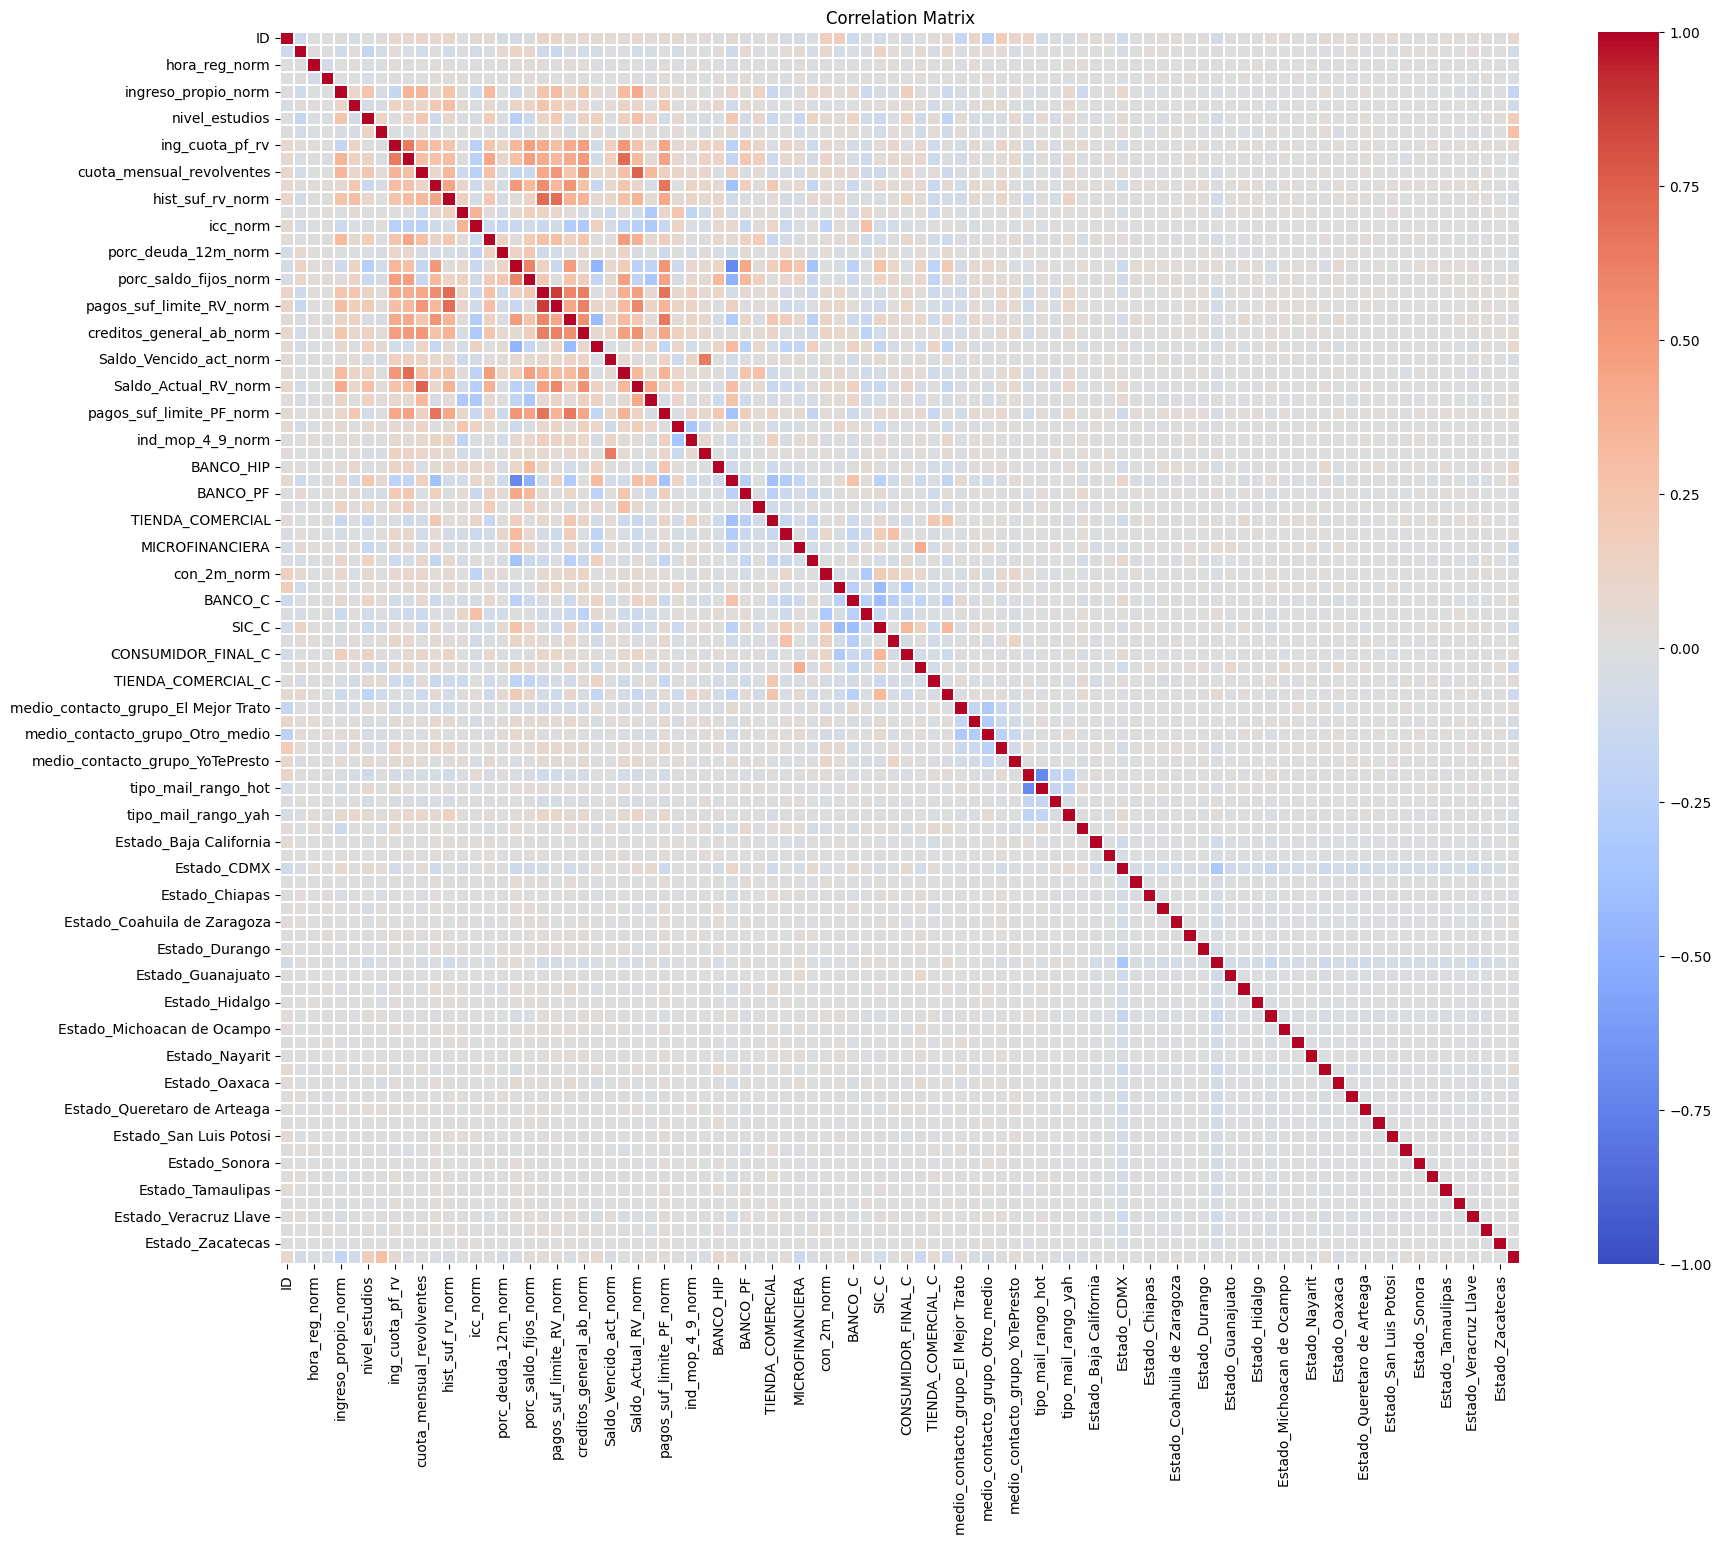

In [32]:
plt.figure(figsize = (20, 16))

sns.heatmap(
    tabla_corr,
    cmap = "coolwarm",
    center = 0,
    vmin = -1,
    vmax = 1,
    annot = False,
    linewidths = 0.05,
    cbar = True
)

plt.title("Correlation Matrix")
plt.show()

Emphasis on the target "ind_malo".

In [33]:
target_corr = (
    df_corr
    .corr()["ind_malo"]
    .drop("ind_malo")
    .sort_values(key = abs, ascending = False)
)

In [34]:
target_corr.head(15)

,ind_malo
nivel_estudios,-0.171037
pagos_suf_limite_RV_norm,-0.149113
porc_fijos_norm,0.124978
SIC_C,0.123480
ID,-0.110735
BANCO_RV,-0.107539
pagos_suf_limite_norm,-0.106907
ingreso_propio_norm,-0.101230
porc_saldo_fijos_norm,0.092376
act_eco_Empleado,-0.085021


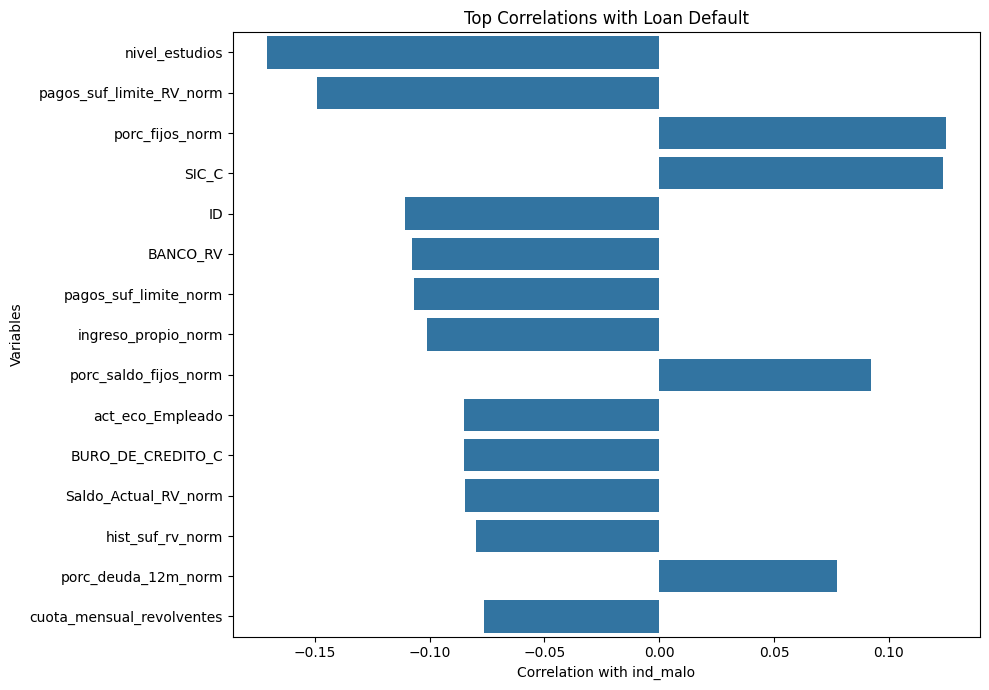

In [35]:
plt.figure(figsize = (10, 7))

sns.barplot(
    x=target_corr.head(15).values,
    y=target_corr.head(15).index
)

plt.title("Top Correlations with Loan Default")
plt.xlabel("Correlation with ind_malo")
plt.ylabel("Variables")

plt.tight_layout()
plt.show()

The same but with key risk variables.

In [36]:
key_numeric_corr = (df[key_numeric_variables + ["ind_malo"]].corr()["ind_malo"].drop("ind_malo").sort_values(key = abs, ascending = False))

In [37]:
display(key_numeric_corr)

,ind_malo
cuota_mensual_revolventes,-0.076367
cuota_mensual_fijos,-0.024607
bc_score_norm,-0.017617
ind_mop_4_9_norm,-0.013720


No individual variable shows a strong linear correlation with the target variable, with the highest absolute correlation being approximately 0.17. Therefore, no predictor is excluded solely based on its correlation with ind_malo, allowing the combined contribution of all available features to be evaluated during modeling.

This decision is also supported by the inclusion of tree-based models such as Random Forest, Gradient Boosting, and XGBoost, which are generally less sensitive to correlated predictors and can capture nonlinear relationships and interactions between variables.

# 2.- Pre-processing

In [38]:
# A copy called df_modelo, of the dataframe was created to maintain traceability.
df_modelo = df.copy()

## 2.1- Drop "ID" column

In [39]:
# "ID" variable will be excluded because it is only an identifier and does not provide meaningful predictive information.
df_modelo = df_modelo.drop(columns = ["ID"])

## 2.2- Imputation of missing values but ...

In [40]:
# To avoid introducing too much noise into the model, missing values ​​were imputed using the median, as it is more robust to outliers.
ingreso_propio_norm_mediana = df_modelo["ingreso_propio_norm"].median()
ing_cuota_pf_rv_mediana = df_modelo["ing_cuota_pf_rv"].median()

In [41]:
#df_modelo["ingreso_propio_norm"] = df_modelo["ingreso_propio_norm"].fillna(ingreso_propio_norm_mediana)
#df_modelo["ing_cuota_pf_rv"] = df_modelo["ing_cuota_pf_rv"].fillna(ing_cuota_pf_rv_mediana)

But to avoid data leakage, the imputation will not be performed at this step.

## 2.3.- Catagorical variable "nivel_estudios"

In [42]:
df_modelo["nivel_estudios"].value_counts()

,count
nivel_estudios,
Licenciatura,8042
Bachillerato,3975
Secundaria,923
Maestria,893
Primaria,141
Doctorado,88
Sin estudios,5


A manual ordinal encoding is applied to this variable based on educational level.

In [43]:
dicc_estudios = {
    "Sin estudios": 0,
    "Primaria": 1,
    "Secundaria": 2,
    "Bachillerato": 3,
    "Licenciatura": 4,
    "Maestria": 5,
    "Doctorado": 6
}

In [44]:
df_modelo["nivel_estudios"] = df_modelo["nivel_estudios"].map(dicc_estudios)

In [45]:
df_modelo["nivel_estudios"].value_counts()

,count
nivel_estudios,
4,8042
3,3975
2,923
5,893
1,141
6,88
0,5


# 3.- Split data

In [46]:
random_seed = 29

In [47]:
# Features and target are defined.
X = df_modelo.drop(columns = ["ind_malo"])
y = df_modelo["ind_malo"]

## 3.1.- Train dataset

In [48]:
# First split: 70% train and 30% temporary set.
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size = 0.30,
    stratify = y,
    random_state = random_seed
)

## 3.2.- Test and validation dataset

In [49]:
# Second split: the temporary set is divided equally into validation and test sets.
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size = 0.50,
    stratify = y_temp,
    random_state = random_seed
)

In both cases we use "stratify" is used to preserve orignal target distribution.

In [50]:
# A brief look at the new datasets.
print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (9846, 53) (9846,)
Validation: (2110, 53) (2110,)
Test: (2111, 53) (2111,)


In [51]:
# The target distribution is displayed after the data split.
print("\nTrain dataset - Target distribution")
print((y_train.value_counts(normalize = True) * 100).round(2).astype(str) + "%")

print("\nTest dataset - Target distribution")
print((y_test.value_counts(normalize = True) * 100).round(2).astype(str) + "%")


print("\nValidation dataset - Target distribution")
print((y_validation.value_counts(normalize = True) * 100).round(2).astype(str) + "%")


Train dataset - Target distribution
ind_malo
0    78.88%
1    21.12%
Name: proportion, dtype: object

Test dataset - Target distribution
ind_malo
0    78.87%
1    21.13%
Name: proportion, dtype: object

Validation dataset - Target distribution
ind_malo
0    78.91%
1    21.09%
Name: proportion, dtype: object


The target distribution is preserved across all datasets, approximately 21% "Default" and 79% "Paid on Time".

## 3.3- Handling of missing values and normalization to avoid lekeage

In [52]:
# Missing values will be imputed using the median, as it is more robust to outliers.
# The imputation values will be calculated using only the training set to avoid data leakage.
ingreso_propio_norm_mediana = X_train["ingreso_propio_norm"].median()
ing_cuota_pf_rv_mediana = X_train["ing_cuota_pf_rv"].median()

In [53]:
# The same training medians are used to impute missing values in train, validation, and test sets.
# Variable "ingreso_propio_norm"
X_train["ingreso_propio_norm"] = X_train["ingreso_propio_norm"].fillna(ingreso_propio_norm_mediana)
X_validation["ingreso_propio_norm"] = X_validation["ingreso_propio_norm"].fillna(ingreso_propio_norm_mediana)
X_test["ingreso_propio_norm"] = X_test["ingreso_propio_norm"].fillna( ingreso_propio_norm_mediana)
# Variable "ing_cuota_pf_rv"
X_train["ing_cuota_pf_rv"] = X_train["ing_cuota_pf_rv"].fillna(ing_cuota_pf_rv_mediana)
X_validation["ing_cuota_pf_rv"] = X_validation["ing_cuota_pf_rv"].fillna(ing_cuota_pf_rv_mediana)
X_test["ing_cuota_pf_rv"] = X_test["ing_cuota_pf_rv"].fillna(ing_cuota_pf_rv_mediana)

Missing values were imputed using median values calculated exclusively from the training set. The same values were then applied to the validation and test sets to prevent data leakage.

In [54]:
numeric_to_scale = ["cuota_mensual_fijos", "cuota_mensual_revolventes"]

In [55]:
# To keep [0, 1] range in numerical variables Max Min Scaler is used.
scaler = MinMaxScaler()

# The scaler is fitted using only the training set.
scaler.fit(X_train[numeric_to_scale])

MinMaxScaler()

In [56]:
# The same transformation is applied to all datasets.
X_train[numeric_to_scale] = scaler.transform(X_train[numeric_to_scale])
X_validation[numeric_to_scale] = scaler.transform(X_validation[numeric_to_scale])
X_test[numeric_to_scale] = scaler.transform(X_test[numeric_to_scale])

In [57]:
display(X_train[numeric_to_scale].describe().loc[["min", "max"]])

,cuota_mensual_fijos,cuota_mensual_revolventes
min,0.0,0.0
max,1.0,1.0


The non-normalized numerical variables were scaled using MinMaxScaler. The scaler was fitted exclusively on the training set and then applied to the validation and test sets to prevent data leakage.

## 3.4.- Encoders

In [66]:
# One-Hot Encoding is applied because the categorical variables have relatively low cardinality.
encoder = OneHotEncoder(
    # drop = "first", avoids perfect multicollinearity between dummy variables.
    drop = "first",
    # handle_unknown = "ignore", prevents errors if validation or test contain unseen categories.
    handle_unknown = "ignore",
    # sparse_output = False, returns a regular NumPy array instead of a sparse matrix.
    sparse_output = False
)

In [68]:
categorical_columns = [
    "dia_reg",
    "medio_contacto_grupo",
    "tipo_mail_rango",
    "sexo",
    "Estado",
    "destino",
    "act_eco"
]

In [69]:
# The encoder is fitted using only the training set to avoid data leakage.
encoder.fit(X_train[categorical_columns])

OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)

In [70]:
encoded_columns = encoder.get_feature_names_out(categorical_columns)

In [71]:
# The categories learned from the training set are displayed.
for column, categories in zip(
    categorical_columns,
    encoder.categories_
):
    print(f"\n{column}:")
    print(categories)


dia_reg:
[1 2 3 4 5 6 7]

medio_contacto_grupo:
['Campana GL' 'El Mejor Trato' 'Facebook' 'Otro_medio' 'SOLCREDITO'
 'YoTePresto']

tipo_mail_rango:
['correo_otro' 'gma' 'hot' 'out' 'yah']

sexo:
['Hombre' 'Mujer']

Estado:
['Aguascalientes' 'Baja California' 'Baja California Sur' 'CDMX'
 'Campeche' 'Chiapas' 'Chihuahua' 'Coahuila de Zaragoza' 'Colima'
 'Durango' 'Estado de México' 'Guanajuato' 'Guerrero' 'Hidalgo' 'Jalisco'
 'Michoacan de Ocampo' 'Morelos' 'Nayarit' 'Nuevo Leon' 'Oaxaca' 'Puebla'
 'Queretaro de Arteaga' 'Quintana Roo' 'San Luis Potosi' 'Sinaloa'
 'Sonora' 'Tabasco' 'Tamaulipas' 'Tlaxcala' 'Veracruz Llave' 'Yucatan'
 'Zacatecas']

destino:
[ 1  2  3  4  5  6  7  8  9 10 11]

act_eco:
['Comerciante' 'Empleado']


In [72]:
print(f"Number of encoded features: {len(encoder.get_feature_names_out(categorical_columns))}\n")

Number of encoded features: 58



In [73]:
# The names of the encoded features are obtained.
encoded_columns = encoder.get_feature_names_out(categorical_columns)

print(f"Number of encoded features: "
    f"{len(encoded_columns)}")

encoded_columns

Number of encoded features: 58


array(['dia_reg_2', 'dia_reg_3', 'dia_reg_4', 'dia_reg_5', 'dia_reg_6',
       'dia_reg_7', 'medio_contacto_grupo_El Mejor Trato',
       'medio_contacto_grupo_Facebook', 'medio_contacto_grupo_Otro_medio',
       'medio_contacto_grupo_SOLCREDITO',
       'medio_contacto_grupo_YoTePresto', 'tipo_mail_rango_gma',
       'tipo_mail_rango_hot', 'tipo_mail_rango_out',
       'tipo_mail_rango_yah', 'sexo_Mujer', 'Estado_Baja California',
       'Estado_Baja California Sur', 'Estado_CDMX', 'Estado_Campeche',
       'Estado_Chiapas', 'Estado_Chihuahua',
       'Estado_Coahuila de Zaragoza', 'Estado_Colima', 'Estado_Durango',
       'Estado_Estado de México', 'Estado_Guanajuato', 'Estado_Guerrero',
       'Estado_Hidalgo', 'Estado_Jalisco', 'Estado_Michoacan de Ocampo',
       'Estado_Morelos', 'Estado_Nayarit', 'Estado_Nuevo Leon',
       'Estado_Oaxaca', 'Estado_Puebla', 'Estado_Queretaro de Arteaga',
       'Estado_Quintana Roo', 'Estado_San Luis Potosi', 'Estado_Sinaloa',
       'Estado_Son

In [74]:
# The same encoder is applied to all datasets.
X_train_encoded = encoder.transform(X_train[categorical_columns])

X_validation_encoded = encoder.transform(X_validation[categorical_columns])

X_test_encoded = encoder.transform(X_test[categorical_columns])

In [75]:
# Encoded arrays are converted into DataFrames to preserve feature names.
X_train_encoded = pd.DataFrame(
    X_train_encoded,
    columns = encoded_columns,
    index = X_train.index
)

X_validation_encoded = pd.DataFrame(
    X_validation_encoded,
    columns = encoded_columns,
    index = X_validation.index
)

X_test_encoded = pd.DataFrame(
    X_test_encoded,
    columns = encoded_columns,
    index = X_test.index
)

In [76]:
# Original categorical variables are removed from the datasets.
X_train_numeric = X_train.drop(columns = categorical_columns)

X_validation_numeric = X_validation.drop(columns = categorical_columns)

X_test_numeric = X_test.drop(columns = categorical_columns)

In [77]:
# Numerical and encoded categorical features are combined.
X_train_final = pd.concat([X_train_numeric, X_train_encoded],axis = 1)

X_validation_final = pd.concat([X_validation_numeric,  X_validation_encoded], axis = 1)

X_test_final = pd.concat([X_test_numeric,  X_test_encoded], axis = 1)

In [79]:
# Final dataset dimensions are checked.

print("Train:", X_train_final.shape)
print("Validation:", X_validation_final.shape)
print("Test:", X_test_final.shape)

Train: (9846, 104)
Validation: (2110, 104)
Test: (2111, 104)


# 4.- Modeling

## 4.1.- Logistic Regression

In [80]:
lr_model = LogisticRegression(
    # max_iter = 1000, provides sufficient margin for the algorithm to converge.
    max_iter = 1000,
    # class_weight = "balanced", The relative weight of the minority class (Default) increases according to its frequency.
    class_weight = "balanced",
    # Maintains reproducibility.
    random_state = random_seed
)

In [81]:
lr_model.fit(
    X_train_final,
    y_train
)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=29)

In [82]:
lr_model.classes_

array([0, 1])

In [83]:
# Default probabilities are predicted using the validation dataset.
lr_validation_probs = lr_model.predict_proba(X_validation_final)[:, 1]

## 4.2.- XGBoost

In [84]:
# The imbalance ratio is calculated using the majority and minority classes in the training set.
tasa_desbalance = (y_train == 0).sum() / (y_train == 1).sum()

print(f"Imbalance ratio: {tasa_desbalance:.2f}")

Imbalance ratio: 3.74


In [85]:
xgboost_model = xgb.XGBClassifier(
    # n_estimators = 200, to compensate for the slow advance, it is adjusted to 200 trees for finer calibration.
    n_estimators = 200,
    # A maximum depth of 5 to balance learning capacity and overfitting.
    max_depth = 5,
    # With a learning_rate = 0.05,reduces the contribution of each new tree for more gradual learning.
    learning_rate = 0.05,
    # scale_pos_weight = 3.74, gives greater weight to the minority class.
    scale_pos_weight = tasa_desbalance,
    # eval_metric = "logloss" evaluates the performance of probabilistic classification and penalizes confident incorrect predictions more strongly.
    eval_metric = "logloss",
    # Maintains reproducibility.
    random_state = random_seed
)

In [86]:
xgboost_model.fit(
    X_train_final,
    y_train
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=None,
              num_parallel_tree=None, ...)

In [87]:
xgboost_model.classes_

array([0, 1])

In [88]:
xgboost_validation_probs = xgboost_model.predict_proba(X_validation_final)[:, 1]

## 4.3.- Random forest

In [89]:
random_forest_model = RandomForestClassifier(
    # n_estimators = 200, defines the number of decision trees used in the ensemble.
    n_estimators = 200,
    # max_depth = 6, limits tree complexity to help reduce overfitting.
    max_depth = 6,
    # class_weight = "balanced", adjusts class weights according to their frequency in the training set.
    class_weight = "balanced",
    # Maintains reproducibility.
    random_state = random_seed
)

In [90]:
random_forest_model.fit(
    X_train_final,
    y_train
)

RandomForestClassifier(class_weight='balanced', max_depth=6, n_estimators=200,
                       random_state=29)

In [91]:
random_forest_model.classes_

array([0, 1])

In [92]:
# Default probabilities are predicted using the validation dataset.
random_forest_validation_probs = random_forest_model.predict_proba(X_validation_final)[:, 1]

## 4.4.- Gradient boosting

In [93]:
gradient_boosting_model = GradientBoostingClassifier(
    # n_estimators = 150, defines the number of sequential boosting stages.
    n_estimators = 150,
    # max_depth = 4, limits the complexity of each individual decision tree.
    max_depth = 4,
    # learning_rate = 0.1, controls the contribution of each new tree to the ensemble.
    learning_rate = 0.1,
    # Maintains reproducibility.
    random_state = random_seed
)

In [94]:
gradient_boosting_model.fit(
    X_train_final,
    y_train
)

GradientBoostingClassifier(max_depth=4, n_estimators=150, random_state=29)

In [95]:
gradient_boosting_model.classes_

array([0, 1])

In [96]:
gradient_boosting_validation_probs = gradient_boosting_model.predict_proba(X_validation_final)[:, 1]

## 4.5.- Model performance metrics

ROC-AUC, Gini, and K-S were selected because the objective of this credit risk problem is not only to assign a final class using a fixed threshold, but also to correctly rank customers according to their probability of default. This is particularly important in an imbalanced classification problem, where metrics such as accuracy may provide a misleading view of model performance.

In [97]:
def calcular_metricas_riesgo(y_true, y_prob, nombre_modelo, dataset_name):
    # AUC measures the model's ability to discriminate between both classes.
    auc = roc_auc_score(y_true, y_prob)

    # Gini is derived directly from AUC.
    gini = 2 * auc - 1

    # ROC curve values are calculated to obtain the K-S statistic.
    fpr, tpr, thresholds = roc_curve(y_true, y_prob)

    # K-S represents the maximum separation between both classes.
    ks = np.max(tpr - fpr)

    return {
        "Model": nombre_modelo,
        f"AUC ({dataset_name})": round(auc, 4),
        f"Gini ({dataset_name})": round(gini, 4),
        f"K-S ({dataset_name})": round(ks, 4)
    }

ROC-AUC evaluates how well the model discriminates between both classes across multiple classification thresholds. In practical terms, it measures the model's ability to assign a higher risk score to a customer who actually defaults than to one who does not.

Gini expresses the same discriminatory ability as ROC-AUC on a different scale and is commonly used in credit risk modeling to assess the quality of risk ranking.

K-S complements these metrics by measuring the maximum separation between the score distributions of good and bad customers. In credit risk, this helps evaluate whether the model creates clearly differentiated risk groups and can support the definition of operational cutoffs or risk segments.

## 4.6.- Model performance comparison

In [98]:
validation_dict_probs = {
    "Logistic Regression": lr_validation_probs,
    "Random Forest": random_forest_validation_probs,
    "Gradient Boosting": gradient_boosting_validation_probs,
    "XGBoost": xgboost_validation_probs
}

In [99]:
lista_resultados = []
for nombre, probs in validation_dict_probs.items():
    res = calcular_metricas_riesgo(y_validation, probs, nombre, "Validation")
    lista_resultados.append(res)

In [100]:
tabla_performance = pd.DataFrame(lista_resultados)

In [101]:
display(tabla_performance.sort_values(by = "AUC (Validation)", ascending=False))

,Model,AUC (Validation),Gini (Validation),K-S (Validation)
3,XGBoost,0.7059,0.4117,0.3067
2,Gradient Boosting,0.6960,0.3919,0.2834
1,Random Forest,0.6817,0.3635,0.2746
0,Logistic Regression,0.6684,0.3368,0.2537


XGBoost achieved the best validation performance across all three risk metrics, with an AUC of 0.7059, Gini of 0.4117, and K-S of 0.3067. Gradient Boosting showed the second-best performance and remained relatively close to XGBoost, while Random Forest and Logistic Regression obtained lower discrimination metrics.

These results suggest that boosting-based models are better suited to capture the nonlinear relationships and interactions present in the dataset. XGBoost is therefore selected as the strongest baseline model for further optimization, while Gradient Boosting remains a competitive alternative.

# 5.- Fine tuning (Grid Search)

Grid Search was used to systematically optimize the hyperparameters of the four classification models. Instead of relying only on manually selected configurations, this method evaluates multiple parameter combinations and identifies the configuration that provides the best performance according to a predefined metric.

## 5.1.- Initial grid search space

In [102]:
grid_lr = {
    "C": [0.01, 0.1, 1.0, 10.0]
}

In [103]:
grid_xgb = {
    "n_estimators": [100, 200],
    "max_depth": [4, 5, 6],
    "learning_rate": [0.03, 0.05, 0.1]
}

In [104]:
grid_rf = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6, 8]
}

In [105]:
grid_gb = {
    "n_estimators": [100, 150],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.05, 0.1]
}

## 5.2.- Base models for grid search

In [106]:
modelos_base = {
    "Logistic Regression": (
        LogisticRegression(
            max_iter = 1000,
            class_weight = "balanced",
            random_state = random_seed
        ),
        grid_lr
    ),
    "XGBoost": (
        xgb.XGBClassifier(
            scale_pos_weight = tasa_desbalance,
            eval_metric = "logloss",
            random_state = random_seed
        ),
        grid_xgb
    )
    ,"Random Forest": (
        RandomForestClassifier(
            class_weight = "balanced",
            random_state = random_seed
        ),
        grid_rf
    ),
    "Gradient Boosting": (
        GradientBoostingClassifier(
            random_state = random_seed
        ),
        grid_gb
    )
}

## 5.3.- Grid search execution

In [107]:
modelos_optimizados = {}
for nombre, (modelo, grid) in modelos_base.items():
    print(f"Optimizing {nombre}...")

    grid_search = GridSearchCV(
        # estimator defines the model to be optimized.
        estimator = modelo,
        # param_grid defines the combinations of hyperparameters to evaluate.
        param_grid = grid,
        # cv = 3 performs three-fold cross-validation using the training dataset.
        cv = 3,
        # ROC-AUC is used as the optimization metric.
        scoring = "roc_auc",
        # All available CPU cores are used.
        n_jobs = -1
    )

    grid_search.fit(
        X_train_final,
        y_train
    )

    modelos_optimizados[nombre] = grid_search.best_estimator_

    print(
        f"Best parameters for {nombre}: "
        f"{grid_search.best_params_}"
    )

Optimizing Logistic Regression...
Best parameters for Logistic Regression: {'C': 0.1}
Optimizing XGBoost...
Best parameters for XGBoost: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200}
Optimizing Random Forest...
Best parameters for Random Forest: {'max_depth': 8, 'n_estimators': 200}
Optimizing Gradient Boosting...
Best parameters for Gradient Boosting: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 150}


ROC-AUC was used as the optimization criterion because the objective is to improve the models' ability to discriminate and rank customers by default risk. Cross-validation was also incorporated to obtain a more robust estimate of performance, while applying the same optimization process to all four models provides a consistent basis for comparison before selecting the final candidate.

## 5.4.- Optimized model performance comparison

In [108]:
validation_dict_probs_opt = {
    "Logistic Regression": modelos_optimizados["Logistic Regression"].predict_proba(X_validation_final)[:, 1],
    "Random Forest": modelos_optimizados["Random Forest"].predict_proba(X_validation_final)[:, 1],
    "Gradient Boosting": modelos_optimizados["Gradient Boosting"].predict_proba(X_validation_final)[:, 1],
    "XGBoost": modelos_optimizados["XGBoost"].predict_proba(X_validation_final)[:, 1]
}

In [109]:
lista_resultados_opt = []

for nombre, probs in validation_dict_probs_opt.items():
    res = calcular_metricas_riesgo(
        y_validation,
        probs,
        nombre,
        "Validation"
    )

    lista_resultados_opt.append(res)

In [110]:
tabla_performance_opt = pd.DataFrame(lista_resultados_opt)

In [111]:
display(tabla_performance_opt.sort_values(by = "AUC (Validation)", ascending = False))

,Model,AUC (Validation),Gini (Validation),K-S (Validation)
3,XGBoost,0.7032,0.4065,0.2979
2,Gradient Boosting,0.6997,0.3995,0.2937
1,Random Forest,0.6886,0.3773,0.2884
0,Logistic Regression,0.6714,0.3427,0.2660


Grid Search improved the validation performance of Logistic Regression, Random Forest, and Gradient Boosting. However, the optimized XGBoost configuration achieved a slightly lower validation AUC than the original baseline configuration.

Despite this small decrease, XGBoost remained the best-performing model overall. Therefore, both the baseline and optimized XGBoost configurations should be considered before selecting the final model for evaluation on the test dataset.

## 5.5.- Final pick on test set

XGBoost: Baseline vs Optimized grid search

In [112]:
# Baseline XGBoost probabilities on test set.
xgboost_test_probs = xgboost_model.predict_proba(X_test_final)[:, 1]

# Optimized XGBoost probabilities on test set.
xgboost_opt_test_probs = modelos_optimizados["XGBoost"].predict_proba(X_test_final)[:, 1]

In [113]:
test_dict_probs = {
    "XGBoost Baseline": xgboost_test_probs,
    "XGBoost Optimized": xgboost_opt_test_probs
}

In [114]:
test_results = []

for nombre, probs in test_dict_probs.items():

    res = calcular_metricas_riesgo(
        y_test,
        probs,
        nombre,
        "Test"
    )

    test_results.append(res)

In [115]:
test_performance = pd.DataFrame(
    test_results
)

In [116]:
display(
    test_performance.sort_values(
        by = "AUC (Test)",
        ascending = False
    )
)

,Model,AUC (Test),Gini (Test),K-S (Test)
1,XGBoost Optimized,0.7285,0.4571,0.3593
0,XGBoost Baseline,0.7234,0.4468,0.3418


Both XGBoost configurations showed consistent discriminatory performance on the test dataset. The optimized XGBoost achieved the best results, with an AUC of 0.7285, Gini of 0.4571, and K-S of 0.3593, outperforming the baseline model across all three metrics.

Although the baseline model showed slightly better performance during validation, the optimized configuration demonstrated stronger performance on the final unseen test set. Overall, the results indicate that XGBoost provides a moderate ability to discriminate between customers who default and those who pay on time.

# 6.- Business strategy based on the results

In [117]:
# Default probabilities are obtained from the optimized XGBoost model using the final test dataset.
probs_xgb_final = modelos_optimizados["XGBoost"].predict_proba(X_test_final)[:, 1]

In [118]:
# A business strategy dataframe is created using actual outcomes and predicted default probabilities.
df_estrategia_final = pd.DataFrame({
    "Real": y_test,
    "Prob_XGB": probs_xgb_final
}, index = X_test_final.index)

In [119]:
df_estrategia_final["Decil_XGB"] = pd.qcut(df_estrategia_final["Prob_XGB"], q = 10, labels = False) + 1

Customers are divided into ten risk groups based on their predicted default probability. Decile 10 the highest predicted risk and decile 1 represents the lowest.

In [120]:
def construir_tabla_negocio(df, columna_decil):
    # Actual defaults and number of customers are aggregated by risk decile.
    tabla = df.groupby(columna_decil).agg(
        Clientes = ("Real", "count"),
        Malos = ("Real", "sum")
    ).reset_index()
    tabla.columns = [
        "Decil",
        "Clientes",
        "Malos_Reales"
    ]
    # Default rate within each decile.
    tabla["Tasa_Malo_Decil"] = (
        tabla["Malos_Reales"] /
        tabla["Clientes"] *
        100
    ).round(2)
    # Deciles are ordered from highest to lowest risk.
    tabla = tabla.sort_values(
        by = "Decil",
        ascending = False
    ).reset_index(drop = True)
    # Cumulative percentage of observed defaults captured from the highest-risk decile.
    tabla["%_Malos_Acum"] = (
        tabla["Malos_Reales"].cumsum() /
        tabla["Malos_Reales"].sum() *
        100
    ).round(2)
    tabla["Tasa_Malo_Decil"] = (
        tabla["Tasa_Malo_Decil"]
        .astype(str) + "%"
    )
    tabla["%_Malos_Acum"] = (
        tabla["%_Malos_Acum"]
        .astype(str) + "%"
    )

    return tabla

## 6.1 Results

Based on the risk deciles generated by the optimized XGBoost model, customers can be segmented into three credit origination groups.

In [121]:
print("=" * 65)
print("        FINAL BUSINESS STRATEGY: XGBOOST RISK DECILES")
print("=" * 65)

display(
    construir_tabla_negocio(
        df_estrategia_final,
        "Decil_XGB"
    )
)

        FINAL BUSINESS STRATEGY: XGBOOST RISK DECILES


,Decil,Clientes,Malos_Reales,Tasa_Malo_Decil,%_Malos_Acum
0,10,211,99,46.92%,22.2%
1,9,211,85,40.28%,41.26%
2,8,211,63,29.86%,55.38%
3,7,211,57,27.01%,68.16%
4,6,211,37,17.54%,76.46%
5,5,211,32,15.17%,83.63%
6,4,211,23,10.9%,88.79%
7,3,211,18,8.53%,92.83%
8,2,211,26,12.32%,98.65%
9,1,212,6,2.83%,100.0%


High Risk — Deciles 8 to 10:
These customers show the highest observed default rates, ranging from 29.86% to 46.92%. Although they represent approximately 30% of the evaluated customers, they concentrate 55.38% of all observed defaults. Applications in this segment could therefore be subject to stricter approval criteria, reduced exposure, or rejection depending on the institution's risk appetite.

Medium Risk — Deciles 5 to 7:
These customers present intermediate default rates, between approximately 15.17% and 27.01%. Credit applications in this segment could require additional validation, lower initial credit limits, or stricter affordability conditions.

Low Risk — Deciles 1 to 4:
These customers show the lowest observed default rates, ranging approximately from 2.83% to 12.32%. Applications within this segment could follow the standard approval process, subject to existing business and eligibility rules.

This strategy demonstrates how the model can be translated from a predictive tool into a risk-based credit origination framework, allowing approval policies to be differentiated according to the estimated probability of default.